# SplitSnap results

Plots every assessment from the saved predictions in `results/predictions/`. Nothing is re-run: each config's
JSON predictions are re-scored with `src/metrics.py`, so the numbers match `results/summary.md` and
`results/vlm_summary_gemini-3.5-flash.md`.

- **CORD test** (100 Indonesian receipts, 268 labeled items): item precision, recall and F1 (name ≥ 80% similar and exact price), subtotal, tax and total accuracy, and checksum pass rate.
- **SRD test** (168 US receipt photos): character error rate (CER, lower is better) against the manual transcriptions (163 images), and total accuracy against the rule-derived total (146 images).

Classic configs use the current code (parser v2). The VLM (Gemini 3.5 Flash) is a reference point only, not part of the pipeline.
Figures are also saved to `figures/results/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_cord, load_srd, srd_split, srd_total_from_text
from metrics import score_cord, score_srd, cer

PRED = Path("../results/predictions")
FIG = Path("../figures/results"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

# folder name -> (short label, group). Order = story order on the plots.
CONFIGS = {
    "B0": ("B0: Tesseract, raw photo", "classic"),
    "+rectify": ("It.1 + rectify", "classic"),
    "+rectify+preprocess": ("It.2 + preprocess", "classic"),
    "+rectify+preprocess+layout": ("It.3 + layout parser", "classic"),
    "EasyOCR: +rectify+layout (no preprocess)": ("It.4-5 EasyOCR, no preprocess (best)", "best"),
    "EasyOCR: +rectify+preprocess+layout": ("Ref: EasyOCR + preprocess", "ref"),
    "preprocess+layout (no rectify)": ("Ref: Tesseract, no rectify", "ref"),
    "oracle-rectify+preprocess+layout": ("Ref: oracle corners (Tesseract)", "ref"),
    "VLM gemini-3.5-flash": ("VLM: Gemini 3.5 Flash", "vlm"),
}
COLORS = {"classic": "#7a8ba6", "best": "#2b6cb0", "ref": "#b8c2d1", "vlm": "#d97706"}

## Load ground truth and predictions

In [2]:
cord_gt = {r["id"]: r["gt"] for r in load_cord("test")}
_, srd_test = srd_split(load_srd())
srd_text = {r["id"]: r["text"] for r in srd_test if r["text"]}
srd_total = {i: srd_total_from_text(t) for i, t in srd_text.items()}

def load_preds(folder, ds, ids):
    d = PRED / folder / ds
    return {i: json.loads((d / f"{i}.json").read_text()) for i in ids}

rows, srd_cer_per, cord_f1_per = [], {}, {}
for folder, (label, group) in CONFIGS.items():
    cp = load_preds(folder, "cord", cord_gt)
    sp = load_preds(folder, "srd", srd_text)
    c, per = score_cord(cp, cord_gt)
    s = score_srd(sp, srd_text, srd_total)
    srd_cer_per[label] = [cer(sp[i]["raw_text"], t) for i, t in srd_text.items()]
    cord_f1_per[label] = [v for v in per.values() if v is not None]
    rows.append({"config": label, "group": group,
                 "CORD P": c["item_P"], "CORD R": c["item_R"], "CORD F1": c["item_F1"],
                 "CORD subtotal": c["subtotal_acc"], "CORD tax": c["tax_acc"], "CORD total": c["total_acc"],
                 "CORD checksum": c["checksum_pass"],
                 "SRD CER mean": s["CER"], "SRD CER median": s["CER_median"], "SRD total": s["total_acc"]})
df = pd.DataFrame(rows).set_index("config")
print(f"CORD: {len(cord_gt)} receipts | SRD: {len(srd_text)} with text, "
      f"{sum(v is not None for v in srd_total.values())} with a usable total")
df.drop(columns="group").style.format("{:.3f}")

CORD: 100 receipts | SRD: 163 with text, 146 with a usable total


,CORD P,CORD R,CORD F1,CORD subtotal,CORD tax,CORD total,CORD checksum,SRD CER mean,SRD CER median,SRD total
config,,,,,,,,,,
"B0: Tesseract, raw photo",0.514,0.134,0.213,0.092,0.098,0.126,0.020,0.393,0.313,0.240
It.1 + rectify,0.526,0.149,0.233,0.123,0.073,0.116,0.030,0.379,0.300,0.329
It.2 + preprocess,0.496,0.257,0.339,0.246,0.146,0.274,0.050,0.245,0.198,0.479
It.3 + layout parser,0.563,0.384,0.457,0.292,0.171,0.305,0.050,0.245,0.198,0.555
"It.4-5 EasyOCR, no preprocess (best)",0.611,0.440,0.512,0.477,0.244,0.474,0.110,0.250,0.188,0.610
Ref: EasyOCR + preprocess,0.614,0.392,0.478,0.400,0.268,0.432,0.110,0.248,0.183,0.610
"Ref: Tesseract, no rectify",0.534,0.377,0.442,0.338,0.195,0.316,0.070,0.265,0.192,0.507
Ref: oracle corners (Tesseract),0.554,0.399,0.464,0.400,0.171,0.295,0.060,0.178,0.132,0.555
VLM: Gemini 3.5 Flash,0.920,0.948,0.934,0.938,0.976,0.989,0.580,0.105,0.044,1.000


In [3]:
def barh(ax, col, title, lower_better=False, xlim=(0, 1)):
    vals = df[col]
    ax.barh(df.index, vals, color=[COLORS[g] for g in df["group"]])
    for y, v in enumerate(vals):
        ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlim(*xlim); ax.invert_yaxis()
    ax.set_title(title + ("  (lower is better)" if lower_better else ""), fontsize=10, loc="left")
    ax.grid(axis="y", visible=False)

def legend(fig):
    from matplotlib.patches import Patch
    names = {"classic": "iteration", "best": "best classic", "ref": "reference run", "vlm": "VLM reference"}
    fig.legend(handles=[Patch(color=COLORS[k], label=v) for k, v in names.items()],
               loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))

## 1. CORD item extraction: F1, precision, recall
The headline metric. An item counts only if its price is exactly right and its name is at least 80% similar.

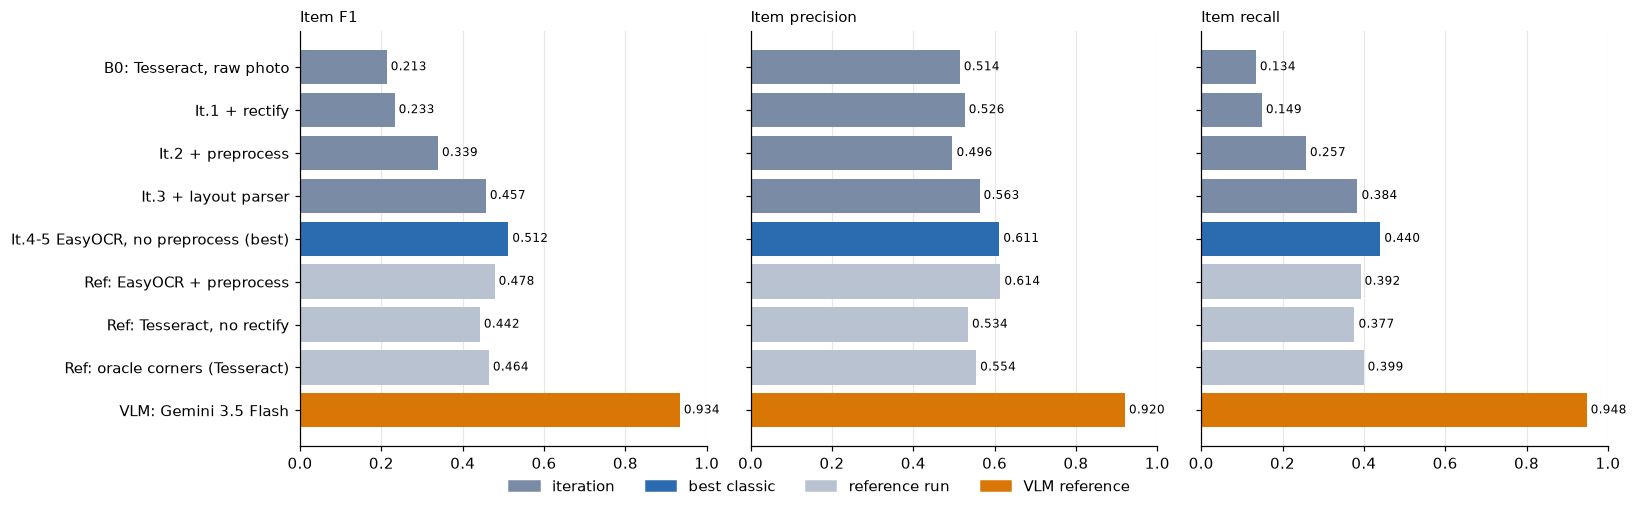

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (col, t) in zip(axes, [("CORD F1", "Item F1"), ("CORD P", "Item precision"), ("CORD R", "Item recall")]):
    barh(ax, col, t)
legend(fig); fig.tight_layout()
fig.savefig(FIG / "cord_items.png", bbox_inches="tight")

## 2. CORD fields: subtotal, tax, total and checksum
The checksum (items add to the subtotal, and subtotal + tax + tip = total, within 0.5%) can pass on at most
54% of receipts, because the ground-truth labels themselves pass on only 54% (discounts, rounding, unlabeled charges).

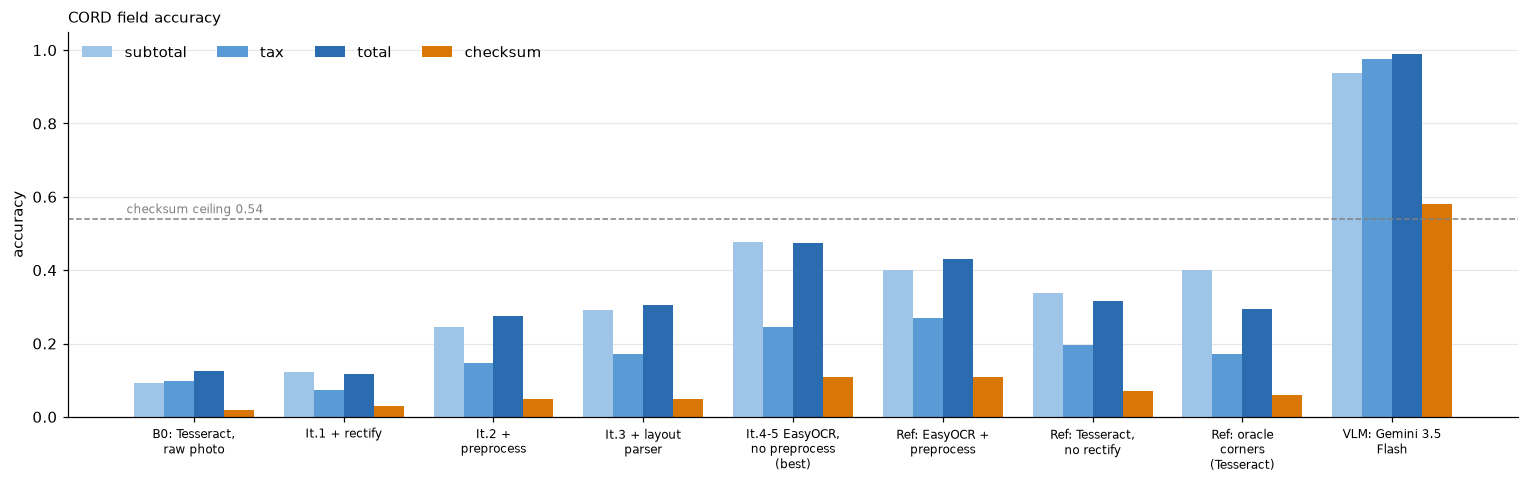

In [5]:
fields = ["CORD subtotal", "CORD tax", "CORD total", "CORD checksum"]
x = np.arange(len(df)); w = 0.2
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, (f, c) in enumerate(zip(fields, ["#9ec5e8", "#5a9bd5", "#2b6cb0", "#d97706"])):
    ax.bar(x + (k - 1.5) * w, df[f], w, label=f.replace("CORD ", ""), color=c)
ax.axhline(0.54, ls="--", color="gray", lw=1); ax.text(-0.45, 0.555, "checksum ceiling 0.54", ha="left", fontsize=8, color="gray")
import textwrap
ax.set_xticks(x, [textwrap.fill(c, 16) for c in df.index], fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("accuracy"); ax.legend(ncol=4, frameon=False)
ax.set_title("CORD field accuracy", loc="left", fontsize=10); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "cord_fields.png", bbox_inches="tight")

## 3. SRD: character error rate and total accuracy
CER = character edits (substitutions + deletions + insertions) needed to turn the OCR text into the manual
transcription, divided by the transcription's length. 0 is perfect. It can exceed 1 when the output is much longer than the reference.

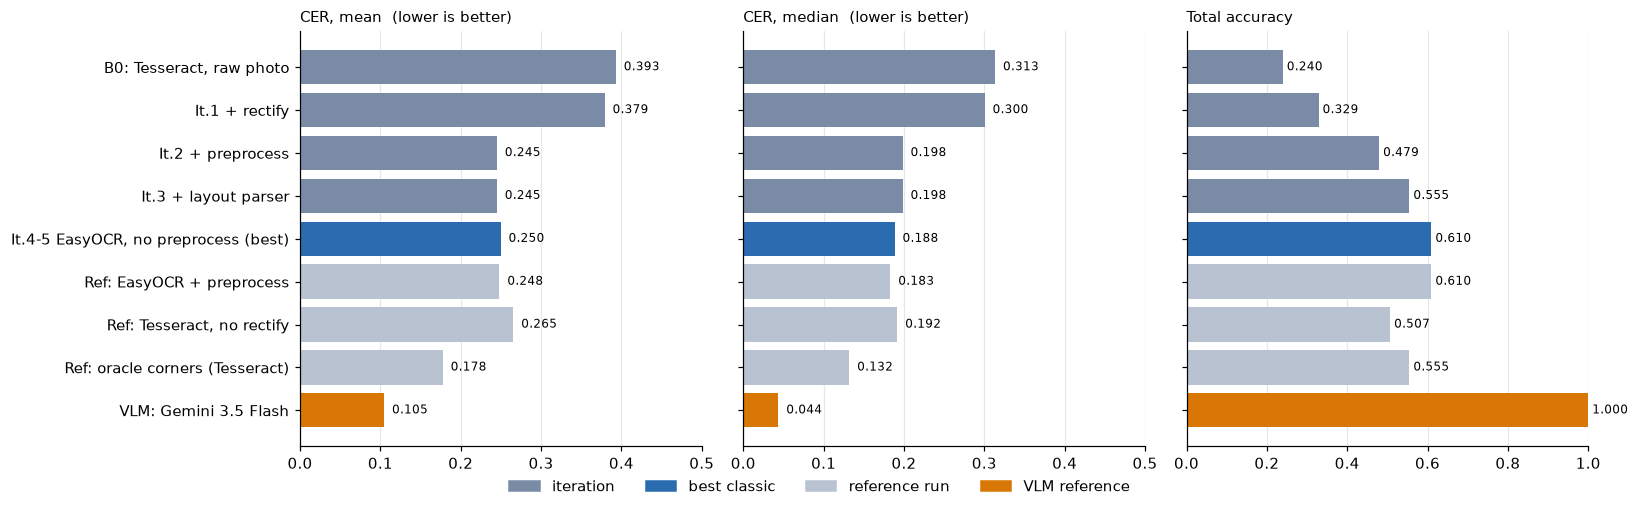

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
barh(axes[0], "SRD CER mean", "CER, mean", lower_better=True, xlim=(0, 0.5))
barh(axes[1], "SRD CER median", "CER, median", lower_better=True, xlim=(0, 0.5))
barh(axes[2], "SRD total", "Total accuracy")
legend(fig); fig.tight_layout()
fig.savefig(FIG / "srd_cer_total.png", bbox_inches="tight")

## 4. SRD CER per receipt
The mean hides a skewed spread: a few receipts with very high CER pull it up. Some of these are bad
references rather than bad reads (e.g. receipt 1045: the transcription is garbled, the VLM reading is correct). Values above 1.2 are clipped to the top edge.

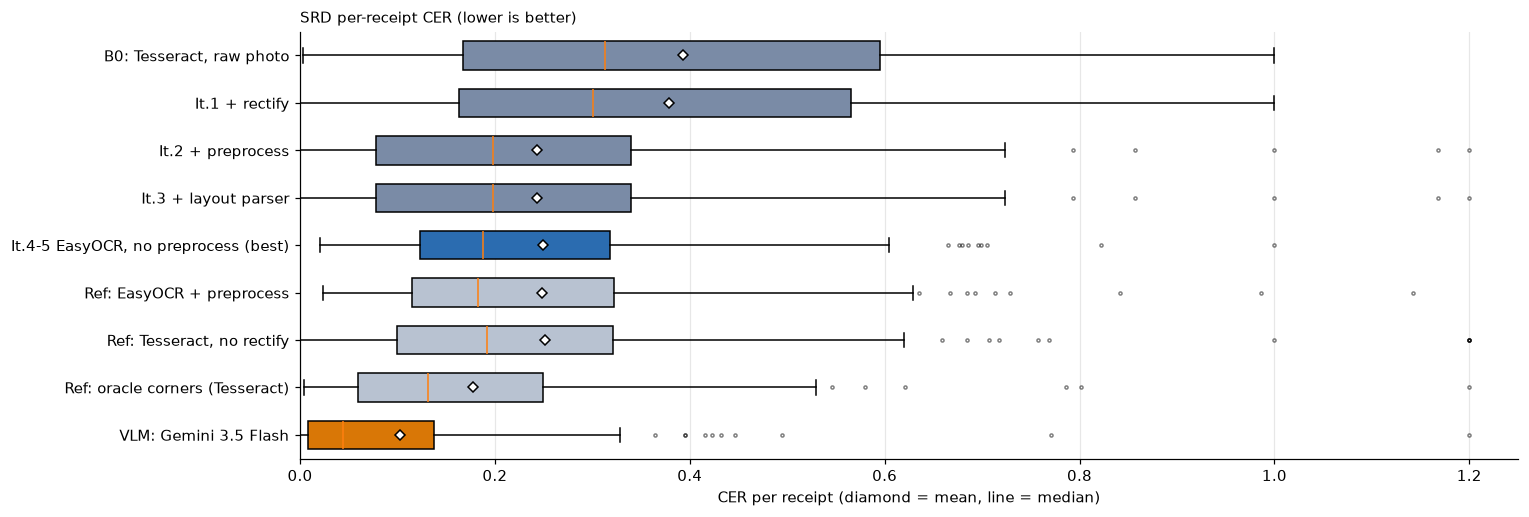

In [7]:
labels = list(df.index)
data = [np.clip([v for v in srd_cer_per[l] if not np.isnan(v)], 0, 1.2) for l in labels]
fig, ax = plt.subplots(figsize=(14, 4.8))
bp = ax.boxplot(data, orientation="horizontal", tick_labels=labels, showmeans=True, patch_artist=True, widths=0.6,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5),
                flierprops=dict(marker=".", markersize=4, alpha=0.5))
for patch, g in zip(bp["boxes"], df["group"]):
    patch.set_facecolor(COLORS[g])
ax.invert_yaxis(); ax.set_xlim(0, 1.25)
ax.set_xlabel("CER per receipt (diamond = mean, line = median)")
ax.set_title("SRD per-receipt CER (lower is better)", loc="left", fontsize=10); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "srd_cer_per_receipt.png", bbox_inches="tight")

In [8]:
worst = pd.DataFrame({"VLM CER": srd_cer_per["VLM: Gemini 3.5 Flash"],
                      "best classic CER": srd_cer_per["It.4-5 EasyOCR, no preprocess (best)"]},
                     index=list(srd_text)).sort_values("VLM CER", ascending=False)
vlm = worst["VLM CER"].dropna()
print(f"VLM mean CER {vlm.mean():.3f}; without the 5 worst receipts {vlm.iloc[5:].mean():.3f}")
worst.head(8).style.format("{:.3f}")

VLM mean CER 0.105; without the 5 worst receipts 0.085


,VLM CER,best classic CER
1045,1.487,0.822
1183,0.771,0.387
1147,0.495,0.273
1074,0.446,0.101
1086,0.432,0.131
1173,0.423,0.193
1139,0.416,0.314
1143,0.396,0.349


## 5. CORD item F1 per receipt

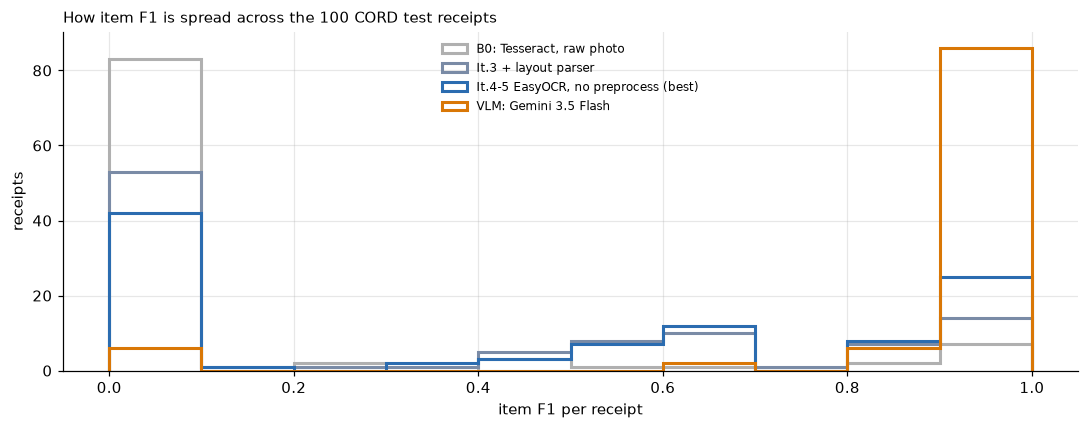

In [9]:
pick = ["B0: Tesseract, raw photo", "It.3 + layout parser", "It.4-5 EasyOCR, no preprocess (best)", "VLM: Gemini 3.5 Flash"]
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 1, 11)
for l in pick:
    ax.hist(cord_f1_per[l], bins=bins, histtype="step", lw=2, label=l,
            color=COLORS[dict(zip(df.index, df["group"]))[l]] if l != "B0: Tesseract, raw photo" else "#b0b0b0")
ax.set_xlabel("item F1 per receipt"); ax.set_ylabel("receipts")
ax.set_title("How item F1 is spread across the 100 CORD test receipts", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); fig.tight_layout()
fig.savefig(FIG / "cord_f1_per_receipt.png", bbox_inches="tight")

## 6. Progress across iterations

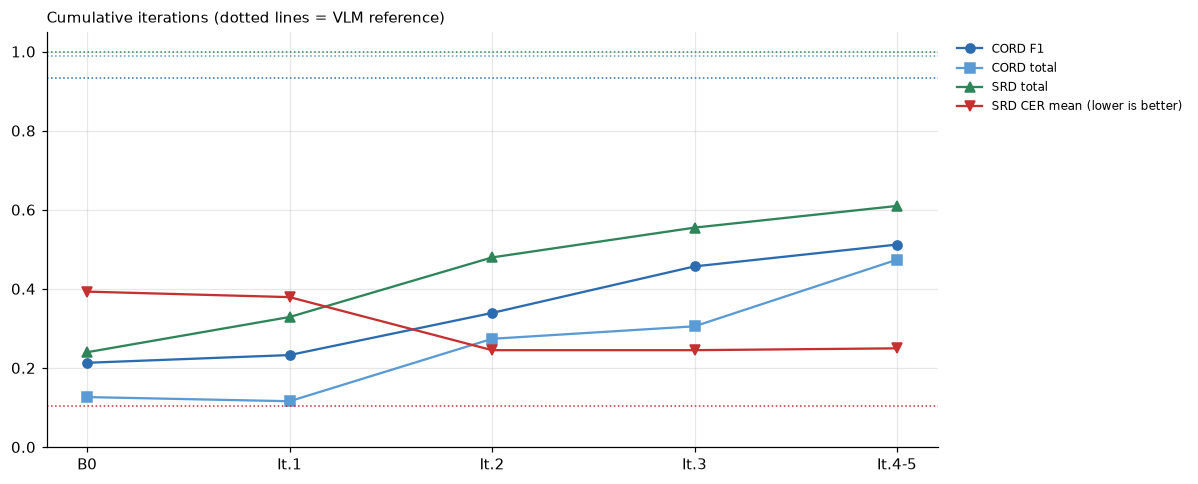

In [10]:
steps = ["B0: Tesseract, raw photo", "It.1 + rectify", "It.2 + preprocess", "It.3 + layout parser",
         "It.4-5 EasyOCR, no preprocess (best)"]
short = ["B0", "It.1", "It.2", "It.3", "It.4-5"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for col, c, m in [("CORD F1", "#2b6cb0", "o"), ("CORD total", "#5a9bd5", "s"),
                  ("SRD total", "#2f855a", "^"), ("SRD CER mean", "#c53030", "v")]:
    ax.plot(short, df.loc[steps, col], marker=m, color=c, label=col + (" (lower is better)" if "CER" in col else ""))
    ax.axhline(df.loc["VLM: Gemini 3.5 Flash", col], color=c, ls=":", lw=1)
ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Cumulative iterations (dotted lines = VLM reference)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "progress.png", bbox_inches="tight")